In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Saving traffic.csv to traffic.csv
Dataset loaded successfully!
Rows: 226278
Columns: 9


,event,date,country,city,artist,album,track,isrc,linkid
0,click,2021-08-21,Saudi Arabia,Jeddah,Tesher,Jalebi Baby,Jalebi Baby,QZNWQ2070741,2d896d31-97b6-4869-967b-1c5fb9cd4bb8
1,click,2021-08-21,Saudi Arabia,Jeddah,Tesher,Jalebi Baby,Jalebi Baby,QZNWQ2070741,2d896d31-97b6-4869-967b-1c5fb9cd4bb8
2,click,2021-08-21,India,Ludhiana,Reyanna Maria,So Pretty,So Pretty,USUM72100871,23199824-9cf5-4b98-942a-34965c3b0cc2
3,click,2021-08-21,France,Unknown,"Simone & Simaria, Sebastian Yatra",No Llores Más,No Llores Más,BRUM72003904,35573248-4e49-47c7-af80-08a960fa74cd
4,click,2021-08-21,Maldives,Malé,Tesher,Jalebi Baby,Jalebi Baby,QZNWQ2070741,2d896d31-97b6-4869-967b-1c5fb9cd4bb8


In [4]:
print("COLUMN NAMES:")
print(df.columns.tolist())

print("\nDATA TYPES:")
print(df.dtypes)

print("\nMISSING VALUES:")
display(df.isnull().sum())

print("\nDUPLICATE ROWS:")
print(df.duplicated().sum())

COLUMN NAMES:
['event', 'date', 'country', 'city', 'artist', 'album', 'track', 'isrc', 'linkid']

DATA TYPES:
event      object
date       object
country    object
city       object
artist     object
album      object
track      object
isrc       object
linkid     object
dtype: object

MISSING VALUES:


,0
event,0
date,0
country,11
city,11
artist,37
album,5
track,5
isrc,7121
linkid,0



DUPLICATE ROWS:
103711


In [5]:
print("Total Records:", len(df))
print("Unique Event Types:", df["event"].nunique())
print("Unique Countries:", df["country"].nunique())
print("Unique Cities:", df["city"].nunique())
print("Unique Artists:", df["artist"].nunique())
print("Unique Tracks:", df["track"].nunique())
print("Unique Links:", df["linkid"].nunique())

print("\nEVENT COUNTS:")
display(df["event"].value_counts())

Total Records: 226278
Unique Event Types: 3
Unique Countries: 211
Unique Cities: 11993
Unique Artists: 2419
Unique Tracks: 3562
Unique Links: 3839

EVENT COUNTS:


,count
event,
pageview,142015
click,55732
preview,28531


In [6]:
clean = df.copy()

# Convert date column
clean["date"] = pd.to_datetime(
    clean["date"],
    errors="coerce"
)

# Remove exact duplicate rows
clean = clean.drop_duplicates()

# Remove rows missing essential information
clean = clean.dropna(
    subset=["event", "date", "linkid"]
)

# Fill missing descriptive values
clean["country"] = clean["country"].fillna("Unknown")
clean["city"] = clean["city"].fillna("Unknown")
clean["artist"] = clean["artist"].fillna("Unknown")
clean["album"] = clean["album"].fillna("Unknown")
clean["track"] = clean["track"].fillna("Unknown")
clean["isrc"] = clean["isrc"].fillna("Unknown")

# Standardize event names
clean["event"] = (
    clean["event"]
    .astype(str)
    .str.strip()
    .str.lower()
)

print("Data cleaning completed successfully!")
print("Rows after cleaning:", len(clean))
print("Duplicate rows remaining:", clean.duplicated().sum())

print("\nMissing values after cleaning:")
display(clean.isnull().sum())

Data cleaning completed successfully!
Rows after cleaning: 122567
Duplicate rows remaining: 0

Missing values after cleaning:


,0
event,0
date,0
country,0
city,0
artist,0
album,0
track,0
isrc,0
linkid,0


In [7]:
clean["Date"] = clean["date"].dt.date
clean["Day"] = clean["date"].dt.day_name()
clean["Month"] = clean["date"].dt.month_name()

print("Date features created successfully!")

display(
    clean[
        ["date", "Date", "Day", "Month", "event", "linkid"]
    ].head()
)

Date features created successfully!


,date,Date,Day,Month,event,linkid
0,2021-08-21,2021-08-21,Saturday,August,click,2d896d31-97b6-4869-967b-1c5fb9cd4bb8
2,2021-08-21,2021-08-21,Saturday,August,click,23199824-9cf5-4b98-942a-34965c3b0cc2
3,2021-08-21,2021-08-21,Saturday,August,click,35573248-4e49-47c7-af80-08a960fa74cd
4,2021-08-21,2021-08-21,Saturday,August,click,2d896d31-97b6-4869-967b-1c5fb9cd4bb8
5,2021-08-21,2021-08-21,Saturday,August,click,190c7170-4044-4c97-9709-926917155b02


In [8]:
event_counts = clean["event"].value_counts()

pageviews = int(event_counts.get("pageview", 0))
clicks = int(event_counts.get("click", 0))
previews = int(event_counts.get("preview", 0))

total_events = len(clean)
unique_links = clean["linkid"].nunique()
unique_countries = clean["country"].nunique()
unique_cities = clean["city"].nunique()

click_rate = (
    clicks / pageviews * 100
    if pageviews > 0 else 0
)

preview_rate = (
    previews / pageviews * 100
    if pageviews > 0 else 0
)

print("========== WEBSITE TRAFFIC KPIs ==========")

print(f"Total Events: {total_events:,}")
print(f"Pageviews: {pageviews:,}")
print(f"Clicks: {clicks:,}")
print(f"Previews: {previews:,}")
print(f"Unique Links: {unique_links:,}")
print(f"Unique Countries: {unique_countries:,}")
print(f"Unique Cities: {unique_cities:,}")

print(f"Click-to-Pageview Rate: {click_rate:.2f}%")
print(f"Preview-to-Pageview Rate: {preview_rate:.2f}%")

========== WEBSITE TRAFFIC KPIs ==========
Total Events: 122,567
Pageviews: 73,360
Clicks: 32,499
Previews: 16,708
Unique Links: 3,839
Unique Countries: 212
Unique Cities: 11,993
Click-to-Pageview Rate: 44.30%
Preview-to-Pageview Rate: 22.78%


In [9]:
print("========== METRIC AVAILABILITY ==========")

print("Sessions: NOT AVAILABLE - no Session ID in dataset")
print("Unique Users: NOT AVAILABLE - no User ID in dataset")
print("Bounce Rate: NOT AVAILABLE - no session-level journey data")
print("Average Session Duration: NOT AVAILABLE - no duration/timestamp data")
print("Referral Sources: NOT AVAILABLE - no referral/source column")

print("\nAvailable engagement metrics:")
print(f"Click-to-Pageview Rate: {click_rate:.2f}%")
print(f"Preview-to-Pageview Rate: {preview_rate:.2f}%")

========== METRIC AVAILABILITY ==========
Sessions: NOT AVAILABLE - no Session ID in dataset
Unique Users: NOT AVAILABLE - no User ID in dataset
Bounce Rate: NOT AVAILABLE - no session-level journey data
Average Session Duration: NOT AVAILABLE - no duration/timestamp data
Referral Sources: NOT AVAILABLE - no referral/source column

Available engagement metrics:
Click-to-Pageview Rate: 44.30%
Preview-to-Pageview Rate: 22.78%


EVENT DISTRIBUTION:


,count
event,
pageview,73360
click,32499
preview,16708


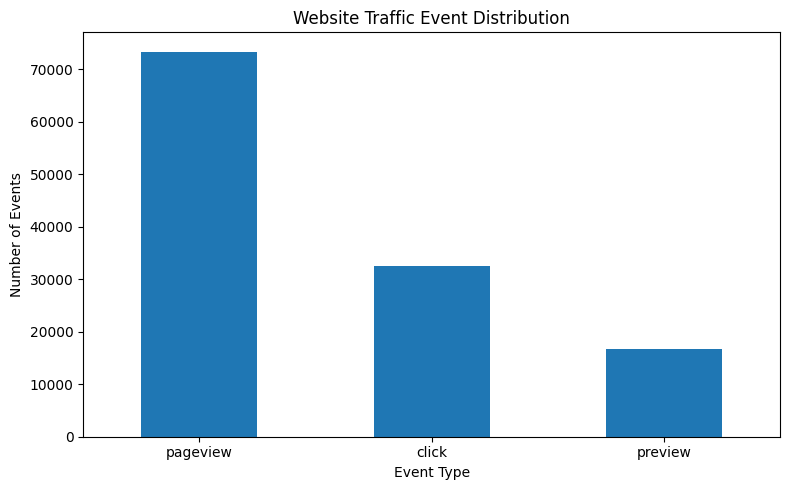

In [10]:
event_counts = clean["event"].value_counts()

print("EVENT DISTRIBUTION:")
display(event_counts)

plt.figure(figsize=(8, 5))

event_counts.plot(kind="bar")

plt.title("Website Traffic Event Distribution")
plt.xlabel("Event Type")
plt.ylabel("Number of Events")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

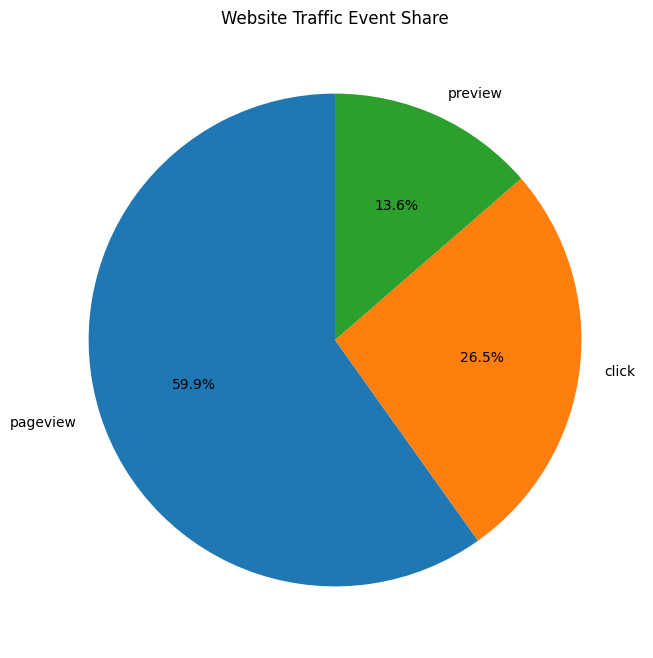

In [11]:
plt.figure(figsize=(8, 8))

plt.pie(
    event_counts.values,
    labels=event_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Website Traffic Event Share")

plt.show()

DAILY WEBSITE TRAFFIC:


,0
Date,
2021-08-19,21156
2021-08-20,18536
2021-08-21,16701
2021-08-22,16927
2021-08-23,16415
2021-08-24,16291
2021-08-25,16541


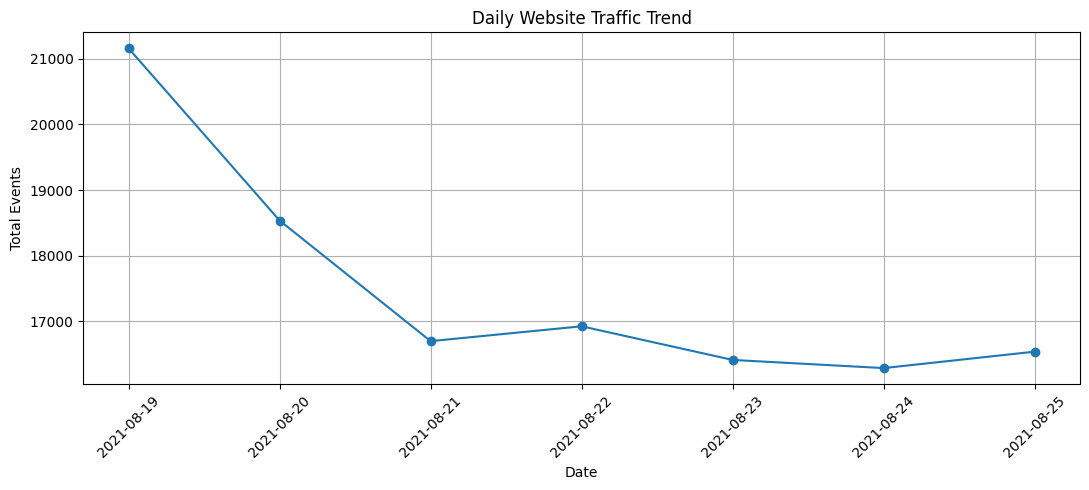

In [12]:
daily_traffic = (
    clean.groupby("Date")
    .size()
    .sort_index()
)

print("DAILY WEBSITE TRAFFIC:")
display(daily_traffic)

plt.figure(figsize=(11, 5))

plt.plot(
    daily_traffic.index.astype(str),
    daily_traffic.values,
    marker="o"
)

plt.title("Daily Website Traffic Trend")
plt.xlabel("Date")
plt.ylabel("Total Events")
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

DAILY USER FLOW:


event,pageview,click,preview
Date,,,
2021-08-19,13006,5860,2290
2021-08-20,11088,4999,2449
2021-08-21,9939,4279,2483
2021-08-22,9982,4421,2524
2021-08-23,9722,4314,2379
2021-08-24,9705,4231,2355
2021-08-25,9918,4395,2228


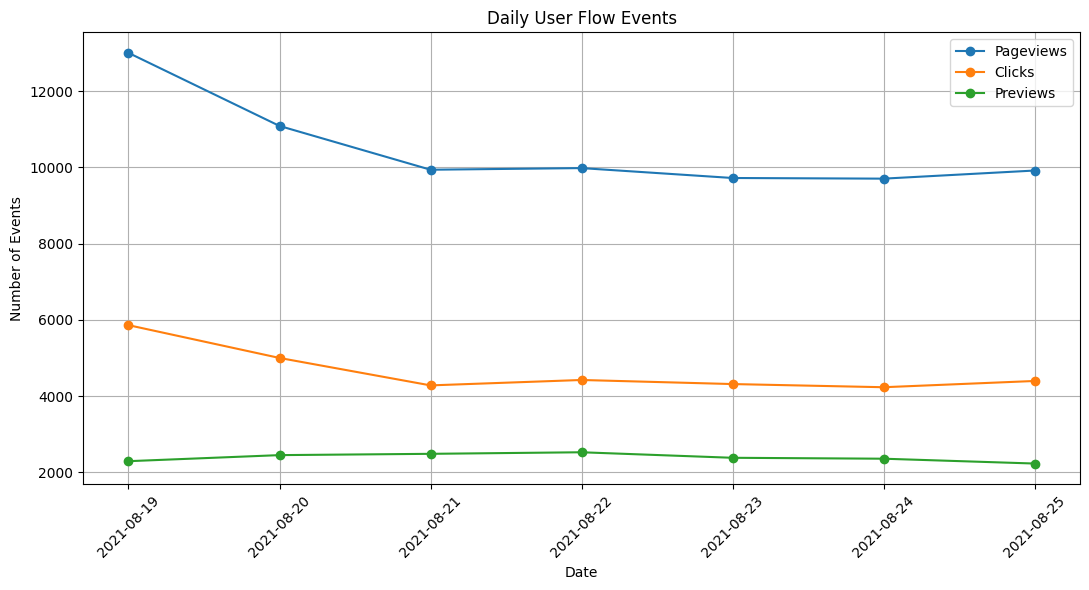

In [13]:
daily_events = pd.crosstab(
    clean["Date"],
    clean["event"]
)

for col in ["pageview", "click", "preview"]:
    if col not in daily_events.columns:
        daily_events[col] = 0

daily_events = daily_events[
    ["pageview", "click", "preview"]
]

print("DAILY USER FLOW:")
display(daily_events)

plt.figure(figsize=(11, 6))

plt.plot(
    daily_events.index.astype(str),
    daily_events["pageview"],
    marker="o",
    label="Pageviews"
)

plt.plot(
    daily_events.index.astype(str),
    daily_events["click"],
    marker="o",
    label="Clicks"
)

plt.plot(
    daily_events.index.astype(str),
    daily_events["preview"],
    marker="o",
    label="Previews"
)

plt.title("Daily User Flow Events")
plt.xlabel("Date")
plt.ylabel("Number of Events")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

USER ENGAGEMENT FUNNEL:


,0
Pageviews,73360
Clicks,32499
Previews,16708


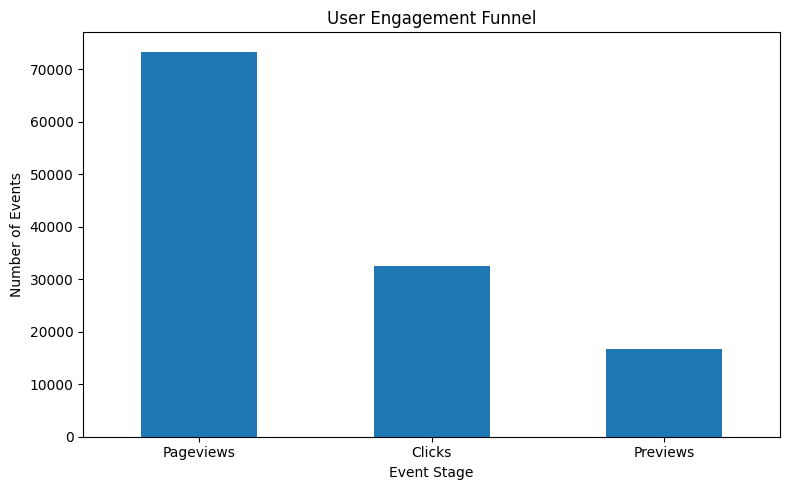

In [14]:
funnel = pd.Series({
    "Pageviews": pageviews,
    "Clicks": clicks,
    "Previews": previews
})

print("USER ENGAGEMENT FUNNEL:")
display(funnel)

plt.figure(figsize=(8, 5))

funnel.plot(kind="bar")

plt.title("User Engagement Funnel")
plt.xlabel("Event Stage")
plt.ylabel("Number of Events")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

TOP 10 COUNTRIES BY TRAFFIC:


,count
country,
United States,28664
India,18689
France,10565
Saudi Arabia,7682
United Kingdom,5095
Germany,4017
Canada,2784
Pakistan,2633
Iraq,2444


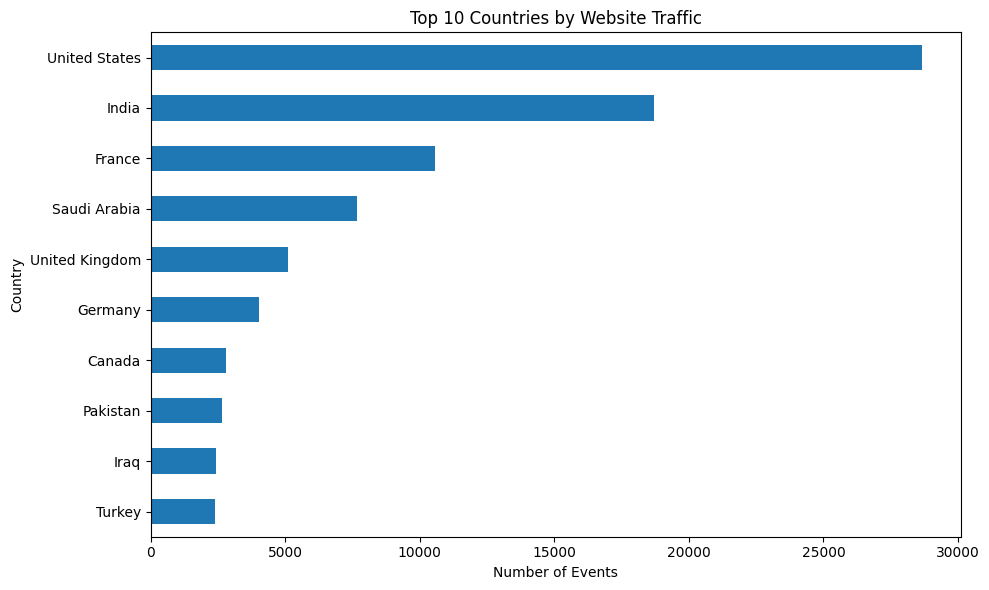

In [15]:
country_traffic = clean["country"].value_counts()

top_countries = country_traffic.head(10)

print("TOP 10 COUNTRIES BY TRAFFIC:")
display(top_countries)

plt.figure(figsize=(10, 6))

top_countries.sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Website Traffic")
plt.xlabel("Number of Events")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

TOP 10 CITIES BY TRAFFIC:


,count
city,
Unknown,8802
Jeddah,2497
Riyadh,2232
Hyderabad,1088
Dammam,1002
Delhi,884
Jaipur,849
Lucknow,837
Kuwait City,816


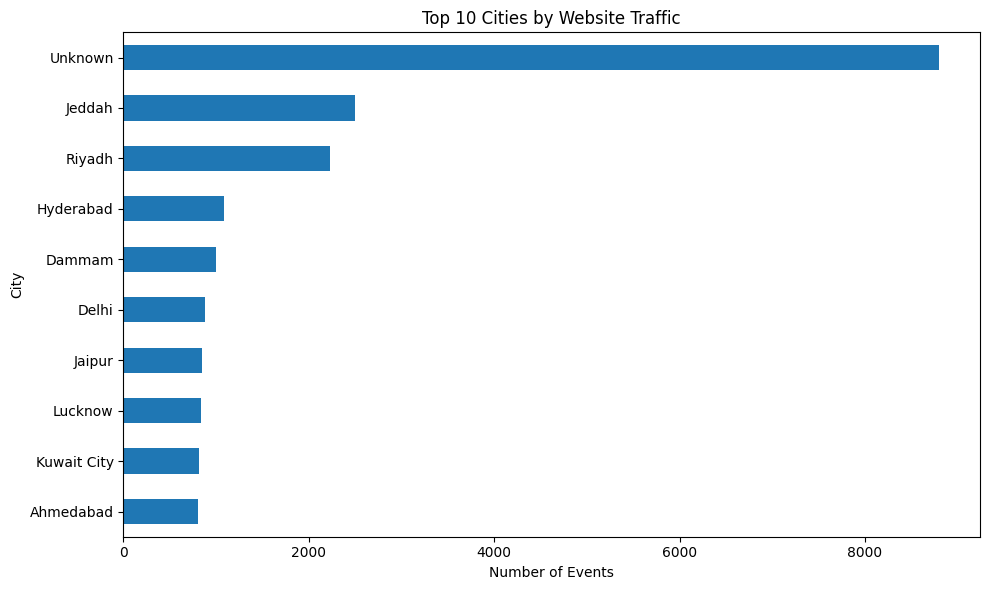

In [16]:
city_traffic = clean["city"].value_counts()

top_cities = city_traffic.head(10)

print("TOP 10 CITIES BY TRAFFIC:")
display(top_cities)

plt.figure(figsize=(10, 6))

top_cities.sort_values().plot(kind="barh")

plt.title("Top 10 Cities by Website Traffic")
plt.xlabel("Number of Events")
plt.ylabel("City")

plt.tight_layout()
plt.show()

TOP 10 LINKS BY PAGEVIEWS:


,count
linkid,
2d896d31-97b6-4869-967b-1c5fb9cd4bb8,4576
522da5cc-8177-4140-97a7-a84fdb4caf1c,2142
e849515b-929d-44c8-a505-e7622f1827e9,2137
a82e72d8-523f-43ab-9fd0-992605d54b4e,1736
681d888a-59ce-4acb-b7c5-95dab0c063d9,1637
23199824-9cf5-4b98-942a-34965c3b0cc2,1559
97105aff-3e40-4c2e-bfeb-563b55e8f5dd,1428
c2c876ab-b093-4750-9449-6b4913da6af3,1391
fbf4b935-f961-4b13-b1d8-45ad47093559,1340


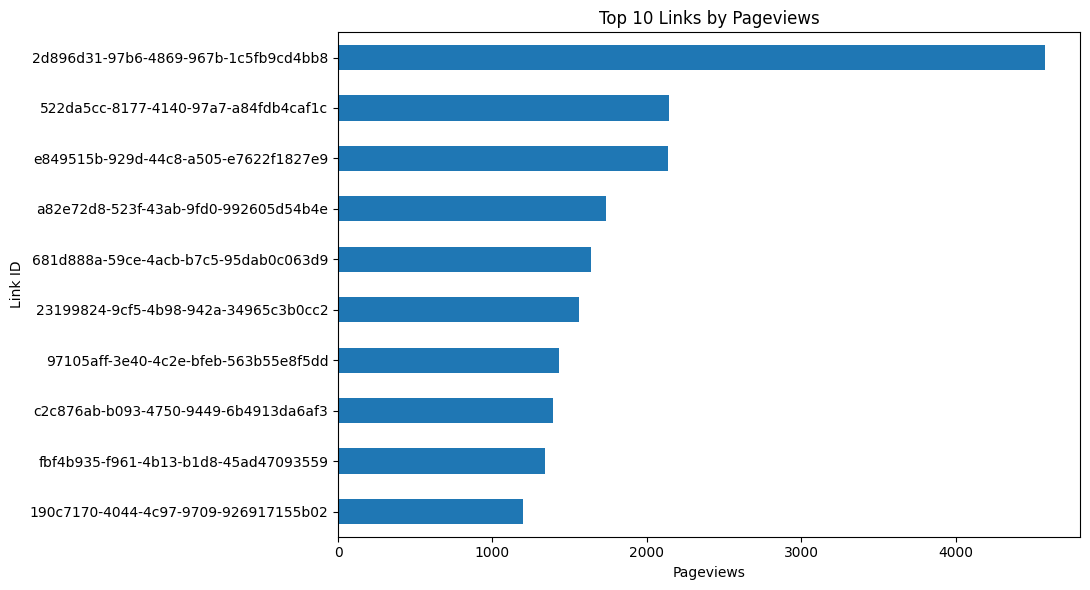

In [17]:
pageview_data = clean[
    clean["event"] == "pageview"
]

top_links_pageviews = (
    pageview_data["linkid"]
    .value_counts()
    .head(10)
)

print("TOP 10 LINKS BY PAGEVIEWS:")
display(top_links_pageviews)

plt.figure(figsize=(11, 6))

top_links_pageviews.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Links by Pageviews")
plt.xlabel("Pageviews")
plt.ylabel("Link ID")

plt.tight_layout()
plt.show()

TOP 10 LINKS BY CLICKS:


,count
linkid,
2d896d31-97b6-4869-967b-1c5fb9cd4bb8,2266
e849515b-929d-44c8-a505-e7622f1827e9,1062
a82e72d8-523f-43ab-9fd0-992605d54b4e,908
522da5cc-8177-4140-97a7-a84fdb4caf1c,891
681d888a-59ce-4acb-b7c5-95dab0c063d9,873
23199824-9cf5-4b98-942a-34965c3b0cc2,684
c2c876ab-b093-4750-9449-6b4913da6af3,579
d5317591-872a-487d-87cb-10a516643d5f,566
97105aff-3e40-4c2e-bfeb-563b55e8f5dd,549


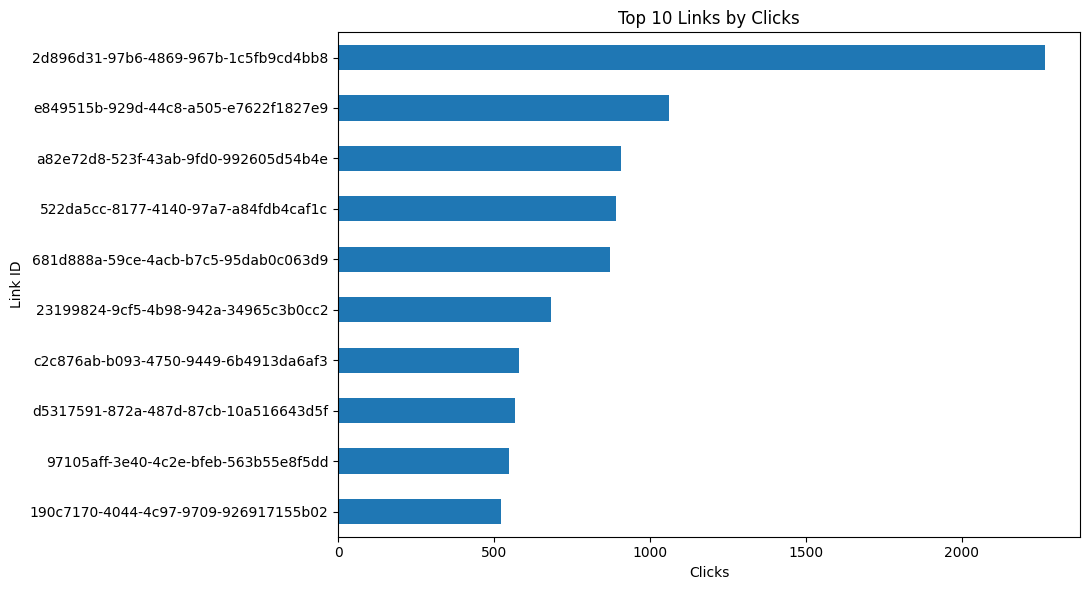

In [18]:
click_data = clean[
    clean["event"] == "click"
]

top_links_clicks = (
    click_data["linkid"]
    .value_counts()
    .head(10)
)

print("TOP 10 LINKS BY CLICKS:")
display(top_links_clicks)

plt.figure(figsize=(11, 6))

top_links_clicks.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Links by Clicks")
plt.xlabel("Clicks")
plt.ylabel("Link ID")

plt.tight_layout()
plt.show()

In [19]:
link_events = pd.crosstab(
    clean["linkid"],
    clean["event"]
)

for col in ["pageview", "click", "preview"]:
    if col not in link_events.columns:
        link_events[col] = 0

link_events["Click_Rate_Percent"] = np.where(
    link_events["pageview"] > 0,
    (link_events["click"] / link_events["pageview"]) * 100,
    np.nan
)

link_events["Preview_Rate_Percent"] = np.where(
    link_events["pageview"] > 0,
    (link_events["preview"] / link_events["pageview"]) * 100,
    np.nan
)

# Minimum 20 pageviews for a more meaningful comparison
eligible_links = link_events[
    link_events["pageview"] >= 20
].copy()

top_engaging_links = (
    eligible_links
    .sort_values(
        "Click_Rate_Percent",
        ascending=False
    )
    .head(10)
)

print("TOP LINKS BY CLICK-TO-PAGEVIEW RATE:")
display(top_engaging_links)

TOP LINKS BY CLICK-TO-PAGEVIEW RATE:


event,click,pageview,preview,Click_Rate_Percent,Preview_Rate_Percent
linkid,,,,,
afe8194e-5002-4e56-bc96-060bf355402d,19,24,1,79.166667,4.166667
ffd3c9e7-c5c5-4f28-b03d-cbaec33f2152,53,67,0,79.104478,0.000000
47f54e58-af71-4580-9182-364b14b7740a,16,21,3,76.190476,14.285714
f2cef536-5a20-4dc1-a973-600051bdea04,23,34,3,67.647059,8.823529
339a61ec-9379-5805-aa3b-baa2f13acb43,19,29,0,65.517241,0.000000
c7ca19fe-a533-4b8a-85c7-faed28ead5e5,13,20,2,65.000000,10.000000
08bc2f1c-5c52-4616-acbd-de4e7a62c7bc,25,39,9,64.102564,23.076923
52762e40-cb7a-4a8a-beb7-03fbd6cca9f8,204,329,66,62.006079,20.060790
51a9a818-40d2-432d-b48a-9dcff61c6278,13,21,1,61.904762,4.761905


TOP 10 TRACKS BY TRAFFIC:


,count
track,
Jalebi Baby,8288
Beautiful,4037
Beautiful Day,3951
Late At Night,3059
ily (i love you baby) (feat. Emilee),2956
Calabria (feat. Lujavo & Nito-Onna),2865
So Pretty,2830
Candy Shop,2397
Summer of Love (Shawn Mendes & Tainy),2108


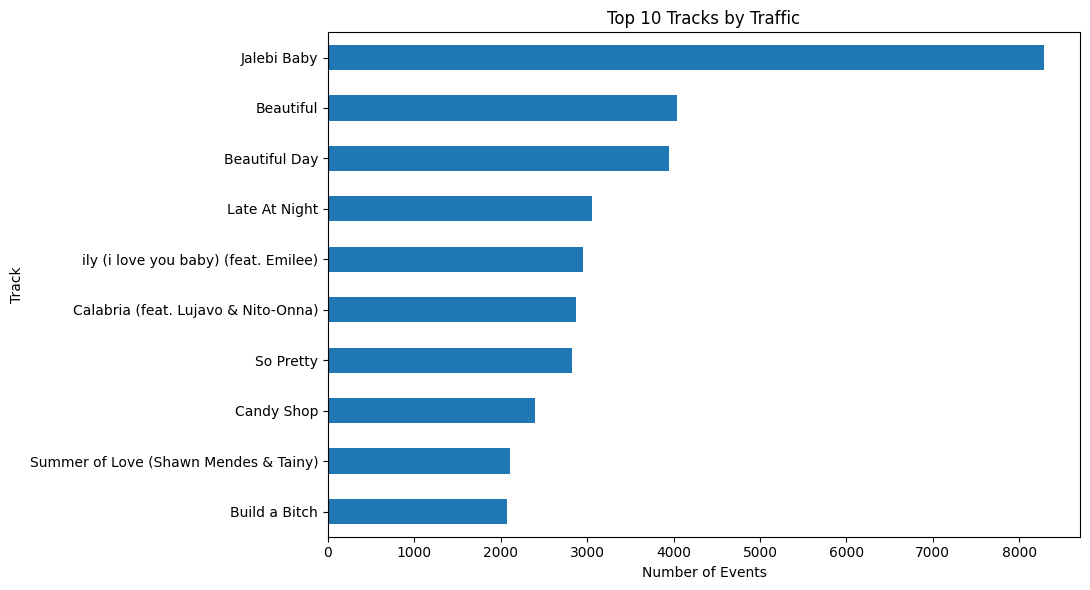

In [21]:
track_traffic = (
    clean[
        clean["track"] != "Unknown"
    ]["track"]
    .value_counts()
)

top_tracks = track_traffic.head(10)

print("TOP 10 TRACKS BY TRAFFIC:")
display(top_tracks)

plt.figure(figsize=(11, 6))

top_tracks.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Tracks by Traffic")
plt.xlabel("Number of Events")
plt.ylabel("Track")

plt.tight_layout()
plt.show()

In [22]:
country_events = pd.crosstab(
    clean["country"],
    clean["event"]
)

for col in ["pageview", "click", "preview"]:
    if col not in country_events.columns:
        country_events[col] = 0

country_events["Click_Rate_Percent"] = np.where(
    country_events["pageview"] > 0,
    (country_events["click"] /
     country_events["pageview"]) * 100,
    np.nan
)

country_events["Preview_Rate_Percent"] = np.where(
    country_events["pageview"] > 0,
    (country_events["preview"] /
     country_events["pageview"]) * 100,
    np.nan
)

country_engagement = (
    country_events[
        country_events["pageview"] >= 100
    ]
    .sort_values(
        "Click_Rate_Percent",
        ascending=False
    )
)

print("TOP COUNTRIES BY CLICK-TO-PAGEVIEW RATE:")
display(country_engagement.head(10))

TOP COUNTRIES BY CLICK-TO-PAGEVIEW RATE:


event,click,pageview,preview,Click_Rate_Percent,Preview_Rate_Percent
country,,,,,
Ghana,191,311,95,61.414791,30.546624
Nigeria,354,636,177,55.660377,27.830189
Pakistan,754,1382,497,54.558611,35.962373
Saudi Arabia,1976,3712,1994,53.232759,53.717672
Mauritania,69,132,39,52.272727,29.545455
Netherlands,430,826,173,52.058111,20.944310
Kenya,93,180,62,51.666667,34.444444
Kuwait,221,433,202,51.039261,46.651270
India,5360,10565,2764,50.733554,26.161855


In [23]:
# Recalculate important values safely

event_counts_final = clean["event"].value_counts()

pageviews_final = int(
    event_counts_final.get("pageview", 0)
)

clicks_final = int(
    event_counts_final.get("click", 0)
)

previews_final = int(
    event_counts_final.get("preview", 0)
)

total_events_final = len(clean)

click_rate_final = (
    clicks_final / pageviews_final * 100
    if pageviews_final > 0 else 0
)

preview_rate_final = (
    previews_final / pageviews_final * 100
    if pageviews_final > 0 else 0
)

country_final = clean["country"].value_counts()
city_final = clean["city"].value_counts()

daily_final = (
    clean.groupby("Date")
    .size()
    .sort_index()
)

top_country = country_final.index[0]
top_country_events = country_final.iloc[0]

top_city = city_final.index[0]
top_city_events = city_final.iloc[0]

highest_date = daily_final.idxmax()
highest_date_events = daily_final.max()

lowest_date = daily_final.idxmin()
lowest_date_events = daily_final.min()

print("=" * 70)
print("FINAL WEBSITE TRAFFIC ANALYSIS SUMMARY")
print("=" * 70)

print(f"\nTotal Clean Events: {total_events_final:,}")
print(f"Pageviews: {pageviews_final:,}")
print(f"Clicks: {clicks_final:,}")
print(f"Previews: {previews_final:,}")

print(
    f"\nClick-to-Pageview Rate: "
    f"{click_rate_final:.2f}%"
)

print(
    f"Preview-to-Pageview Rate: "
    f"{preview_rate_final:.2f}%"
)

print(
    f"\nTop Traffic Country: "
    f"{top_country} ({top_country_events:,} events)"
)

print(
    f"Top Traffic City: "
    f"{top_city} ({top_city_events:,} events)"
)

print(
    f"\nHighest Traffic Date: "
    f"{highest_date} ({highest_date_events:,} events)"
)

print(
    f"Lowest Traffic Date: "
    f"{lowest_date} ({lowest_date_events:,} events)"
)

print("\nDATA LIMITATIONS:")
print("Sessions: Not available - no Session ID")
print("Unique Users: Not available - no User ID")
print("Bounce Rate: Not available - no session-level journey data")
print("Average Session Duration: Not available - no duration data")
print("Referral Sources: Not available - no referral/source column")

print("\nFINAL SUMMARY GENERATED SUCCESSFULLY!")

FINAL WEBSITE TRAFFIC ANALYSIS SUMMARY

Total Clean Events: 122,567
Pageviews: 73,360
Clicks: 32,499
Previews: 16,708

Click-to-Pageview Rate: 44.30%
Preview-to-Pageview Rate: 22.78%

Top Traffic Country: United States (28,664 events)
Top Traffic City: Unknown (8,802 events)

Highest Traffic Date: 2021-08-19 (21,156 events)
Lowest Traffic Date: 2021-08-24 (16,291 events)

DATA LIMITATIONS:
Sessions: Not available - no Session ID
Unique Users: Not available - no User ID
Bounce Rate: Not available - no session-level journey data
Average Session Duration: Not available - no duration data
Referral Sources: Not available - no referral/source column

FINAL SUMMARY GENERATED SUCCESSFULLY!


# 5 Optimization Recommendations for Alfido Tech

### 1. Improve Click Engagement
Alfido Tech should test clearer calls-to-action, stronger link placement and
more relevant content to improve the click-to-pageview rate.

### 2. Optimize High-Traffic Links
Links receiving high pageviews should be prioritized for optimization.
Better calls-to-action and relevant destination content can help convert
existing traffic into stronger engagement.

### 3. Use Geographic Targeting
High-traffic countries and cities should be considered when planning
geographically targeted campaigns and content.

### 4. Promote High-Interest Content
Popular tracks and artists indicate areas of strong audience interest.
Similar content can be promoted to improve user engagement.

### 5. Monitor the Engagement Funnel
Alfido Tech should continuously compare pageviews, clicks and previews.
Links receiving high pageviews but relatively weak downstream engagement
should be tested and optimized first.

# Executive Summary

This project analyzed website traffic event data to understand user
engagement, geographic traffic patterns, high-performing links and popular
content.

The dataset was cleaned by removing duplicate records, converting the date
field and handling missing descriptive values. Traffic events including
pageviews, clicks and previews were analyzed to understand engagement
patterns.

Daily traffic trends and the pageview-click-preview flow were visualized.
Traffic was also analyzed across countries, cities and link IDs to identify
high-traffic areas and high-performing links. Content-level analysis was
performed using track and artist information.

The dataset does not contain Session ID, User ID, session duration,
landing-page URL or referral-source fields. Therefore exact sessions, unique
users, bounce rate, average session duration and referral-source metrics were
not fabricated.

Based on the available data, Alfido Tech should improve calls-to-action,
optimize high-traffic links, use geographic targeting, promote high-interest
content and continuously monitor link-level engagement.

# Conclusion

The Website Traffic Analysis provides a data-driven overview of website
traffic and engagement using the information available in the dataset.

Pageviews, clicks and previews were analyzed to understand the user
engagement flow. Daily trends, geographic performance, link activity and
content popularity were also examined.

The analysis identifies high-traffic areas and content and provides
link-level engagement metrics that can support optimization decisions.

Metrics requiring session-level or user-level information were not estimated
because the required fields were not included in the provided dataset.

Overall, these findings can help Alfido Tech improve link engagement,
content strategy and conversion-focused optimization.

In [24]:
clean.to_csv(
    "cleaned_website_traffic.csv",
    index=False
)

daily_events.to_csv(
    "daily_traffic_summary.csv"
)

link_events.to_csv(
    "link_performance_summary.csv"
)

country_events.to_csv(
    "country_engagement_summary.csv"
)

print("Result files saved successfully!")

Result files saved successfully!


In [25]:
print("========== TASK 3 COMPLETION CHECK ==========")

print("Traffic Data Cleaning: COMPLETED")
print("Missing Value Handling: COMPLETED")
print("Traffic Event Metrics: COMPLETED")
print("Pageview Analysis: COMPLETED")
print("Click Analysis: COMPLETED")
print("Preview Analysis: COMPLETED")
print("Daily Traffic Trend: COMPLETED")
print("User Flow Analysis: COMPLETED")
print("Top Link Analysis: COMPLETED")
print("Country Analysis: COMPLETED")
print("City Analysis: COMPLETED")
print("Content Analysis: COMPLETED")
print("Visualizations: COMPLETED")
print("5 Optimization Recommendations: COMPLETED")
print("Executive Summary: COMPLETED")
print("Conclusion: COMPLETED")

print("\nUnavailable because required columns are absent:")
print("Exact Sessions: NOT AVAILABLE")
print("Exact Unique Users: NOT AVAILABLE")
print("Exact Bounce Rate: NOT AVAILABLE")
print("Average Session Duration: NOT AVAILABLE")
print("Referral Sources: NOT AVAILABLE")

print("\nTASK 3 - WEBSITE TRAFFIC ANALYSIS COMPLETED SUCCESSFULLY!")

========== TASK 3 COMPLETION CHECK ==========
Traffic Data Cleaning: COMPLETED
Missing Value Handling: COMPLETED
Traffic Event Metrics: COMPLETED
Pageview Analysis: COMPLETED
Click Analysis: COMPLETED
Preview Analysis: COMPLETED
Daily Traffic Trend: COMPLETED
User Flow Analysis: COMPLETED
Top Link Analysis: COMPLETED
Country Analysis: COMPLETED
City Analysis: COMPLETED
Content Analysis: COMPLETED
Visualizations: COMPLETED
5 Optimization Recommendations: COMPLETED
Executive Summary: COMPLETED
Conclusion: COMPLETED

Unavailable because required columns are absent:
Exact Sessions: NOT AVAILABLE
Exact Unique Users: NOT AVAILABLE
Exact Bounce Rate: NOT AVAILABLE
Average Session Duration: NOT AVAILABLE
Referral Sources: NOT AVAILABLE

TASK 3 - WEBSITE TRAFFIC ANALYSIS COMPLETED SUCCESSFULLY!
